# So sánh 3 CNN tự xây dựng — Augmented Banana Ripeness
Một notebook chạy tuần tự A → B → C, dùng cùng manifest và lịch huấn luyện. Không tải pretrained weights.

- **A_slide:** theo code trang 51/74 bài giảng: Conv6(5×5,same), Pool, Conv16(5×5,valid), Pool, Flatten, Dense120, Dense84, Softmax4. Đổi đầu vào sang RGB với kích thước chung; không phải sao chép nguyên mẫu MNIST.
- **B_features:** Conv32/64/128 (3×3,same), mỗi Conv có ReLU + Pool; GAP, Dense128, Softmax4.
- **C_bn_dropout:** cùng B, thêm BN trước ReLU ở ba Conv và Dropout0.2 sau Dense128. Không thêm độ sâu hoặc SpatialDropout để so sánh B–C rõ ràng.

Cố định ảnh đầu vào 128×128 cho cả ba notebook để so sánh cùng kích thước và hạn chế phần Flatten của A.

Chọn TRAIN_SEEDS=[42] để chạy thử3 lượt; [42,43,44] để chạy9 lượt. MODEL_NAMES chọn các model muốn chạy. Test mặc định tắt. Restart kernel rồi Run All khi bắt đầu thí nghiệm mới. Mỗi lần Run All tạo thư mục kết quả riêng.


In [1]:
import os, json, random, time, gc, hashlib, shutil
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.config.experimental.enable_op_determinism()
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
DATA_ROOT = "/kaggle/input/datasets/thinhng04/banana-dataset/Augmented Banana Ripeness Detection Dataset/Augmented Banana Ripeness Detection Dataset"  # Thư mục chứa trực tiếp Green, Semi-ripe, Ripe, Overripe
MANIFEST_CSV = "/kaggle/input/datasets/thinhng04/banana-dataset/manifest_used.csv"  # Tự tìm đúng một manifest_used.csv; hoặc đặt đường dẫn tường minh
SPLIT_SEED = 42
TRAIN_SEEDS = [42]  # Đổi thành [42, 43, 44] để đo ổn định
MODEL_NAMES = ["A_slide", "B_features", "C_bn_dropout"]
IMAGE_SIZE = (128, 128)  # Kích thước chung của ba notebook
CLASS_NAMES = ["Green", "Semi-ripe", "Ripe", "Overripe"]
SPLIT_RATIOS = (0.70, 0.15, 0.15)
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
EPOCHS = 60
PATIENCE = 12
DROPOUT_RATE = 0.20
BN_MOMENTUM = 0.90
RUN_TEST = False
SEED = SPLIT_SEED
assert TRAIN_SEEDS and len(set(TRAIN_SEEDS)) == len(TRAIN_SEEDS)
assert MODEL_NAMES and len(set(MODEL_NAMES)) == len(MODEL_NAMES)
assert set(MODEL_NAMES) <= {"A_slide", "B_features", "C_bn_dropout"}
assert min(IMAGE_SIZE) >= 16
base_output = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUTPUT = base_output / ("cnn_ABC_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f"))
OUTPUT.mkdir(parents=True, exist_ok=False)
if DATA_ROOT is None:
    candidates = sorted({p.parent.resolve() for p in Path("/kaggle/input").rglob("Green")
                         if p.is_dir() and all((p.parent / label).is_dir() for label in CLASS_NAMES)})
    if len(candidates) != 1:
        raise ValueError(f"Cần đặt DATA_ROOT; tìm thấy {candidates}")
    DATA_ROOT = candidates[0]
DATA_ROOT = Path(DATA_ROOT).resolve()
assert all((DATA_ROOT / label).is_dir() for label in CLASS_NAMES), "DATA_ROOT không đúng dataset4 lớp"
print("Dataset:", DATA_ROOT)
print("Kết quả:", OUTPUT)


Dataset: /kaggle/input/datasets/thinhng04/banana-dataset/Augmented Banana Ripeness Detection Dataset/Augmented Banana Ripeness Detection Dataset
Kết quả: /kaggle/working/cnn_ABC_20261120_032542_537036


## Manifest dùng chung
Notebook bắt buộc dùng manifest của nhóm; không tự chia lại dữ liệu. Các biến thể cùng source_id phải nằm trong cùng split.


In [3]:
label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}

def source_id(path):
    return Path(path).name.split(".rf.")[0]

if MANIFEST_CSV is None:
    search_root = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path.cwd()
    matches = sorted({p.resolve() for p in search_root.rglob("manifest_used.csv")})
    if not matches:
        raise FileNotFoundError("Không tìm thấy manifest_used.csv. Hãy Add Input manifest hoặc đặt MANIFEST_CSV.")
    if len(matches) > 1:
        raise ValueError(f"Tìm thấy nhiều manifest_used.csv: {matches}. Hãy đặt MANIFEST_CSV tường minh.")
    MANIFEST_CSV = matches[0]
else:
    MANIFEST_CSV = Path(MANIFEST_CSV).resolve()
    if not MANIFEST_CSV.is_file():
        raise FileNotFoundError(MANIFEST_CSV)

raw_manifest = pd.read_csv(MANIFEST_CSV, dtype={"path": str, "label": str, "split": str})
assert {"path", "label", "split"}.issubset(raw_manifest.columns), "Manifest cần cột path,label,split"
assert not raw_manifest[["path", "label", "split"]].isna().any().any(), "Manifest có giá trị trống"
raw_manifest["split"] = raw_manifest["split"].str.lower().str.strip().replace({"val": "valid", "validation": "valid"})
assert set(raw_manifest.split) == {"train", "valid", "test"}, "Manifest phải có train/valid/test"
if "label_id" in raw_manifest.columns:
    pairs = raw_manifest[["label", "label_id"]].drop_duplicates()
    assert not pairs.label.duplicated().any() and not pairs.label_id.duplicated().any(), "Ánh xạ label/label_id không duy nhất"
    observed = dict(zip(pairs.label, pairs.label_id.astype(int)))
    expected = {name: i for i, name in enumerate(CLASS_NAMES)}
    assert observed == expected, f"Ánh xạ label_id trong manifest không khớp: {observed}"

df = raw_manifest[["path", "label", "split"]].copy()
df["source_id"] = df.path.map(source_id)
df["path"] = df.path.map(lambda p: str((DATA_ROOT / p).resolve()))
assert len(df), "Manifest rỗng"
assert set(df.label) == set(CLASS_NAMES), f"Nhãn không khớp: {sorted(df.label.unique())}"
assert not df.path.duplicated().any(), "Đường dẫn ảnh bị lặp"
assert (df.groupby("source_id").split.nunique() == 1).all(), "Rò rỉ source_id giữa các split"
assert (df.groupby("source_id").label.nunique() == 1).all(), "Cùng source_id nhưng khác nhãn"
missing = [p for p in df.path if not Path(p).is_file()]
assert not missing, f"Không tìm thấy ảnh: {missing[:3]}"
df["label_id"] = df.label.map(label_to_id)
df = df.sort_values(["split", "label_id", "path"]).reset_index(drop=True)
counts = pd.crosstab(df.label, df.split).reindex(index=CLASS_NAMES, columns=["train", "valid", "test"], fill_value=0)
assert (counts > 0).all().all(), "Mỗi split cần đủ 4 lớp"
print("Manifest:", MANIFEST_CSV)
print("Số ảnh theo lớp/split:"); display(counts)
print("Số nhóm nguồn:"); display(df.groupby(["label", "split"]).source_id.nunique().unstack().reindex(CLASS_NAMES))
print("Thứ tự nhãn:", label_to_id)
print("Dữ liệu/split lấy nguyên từ manifest; chia theo source_id.")
manifest = df.copy()
manifest["path"] = manifest.path.map(lambda p: Path(p).relative_to(DATA_ROOT).as_posix())
manifest.to_csv(OUTPUT / "manifest_used.csv", index=False)
(OUTPUT / "class_names.json").write_text(json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding="utf-8")
records = manifest[["path", "label", "split"]].sort_values("path").to_csv(index=False, lineterminator="\n")
SPLIT_SHA = hashlib.sha256(records.encode("utf-8")).hexdigest()
config = dict(data_root=str(DATA_ROOT), manifest_csv=str(MANIFEST_CSV),
    manifest_sha256=hashlib.sha256(Path(MANIFEST_CSV).read_bytes()).hexdigest(),
    split_sha256=SPLIT_SHA, train_seeds=TRAIN_SEEDS, models=MODEL_NAMES,
    image_size=list(IMAGE_SIZE), batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
    max_epochs=EPOCHS, early_stopping_patience=PATIENCE, monitor="val_macro_f1",
    lr_scheduler=dict(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, min_delta=0.),
    checkpoint_tiebreak="val_loss", dropout_C=DROPOUT_RATE, bn_momentum_C=BN_MOMENTUM,
    preprocessing="EXIF RGB, bilinear resize_with_pad black padding, model Rescaling 1/255",
    online_augmentation=False, deterministic_ops=True, tensorflow=tf.__version__)
(OUTPUT / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Split fingerprint:", SPLIT_SHA)


Manifest: /kaggle/input/datasets/thinhng04/banana-dataset/manifest_used.csv
Số ảnh theo lớp/split:


split,train,valid,test
label,,,
Green,444,93,99
Semi-ripe,426,90,93
Ripe,420,90,93
Overripe,426,90,93


Số nhóm nguồn:


split,test,train,valid
label,,,
Green,33,148,31
Semi-ripe,31,142,30
Ripe,31,140,30
Overripe,31,142,30


Thứ tự nhãn: {'Green': 0, 'Semi-ripe': 1, 'Ripe': 2, 'Overripe': 3}
Dữ liệu/split lấy nguyên từ manifest; chia theo source_id.
Split fingerprint: fd00e11b0028b8dd68fa9d3441d4e5f14f2cfe62cb853d316148318efb6e47fb


In [4]:
def read_rgb_numpy(path):
    path = path.item() if hasattr(path, "item") else path
    path = path.decode("utf-8") if isinstance(path, bytes) else str(path)
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert("RGB"), dtype=np.uint8)

def load_image(path, label):
    image = tf.numpy_function(read_rgb_numpy, [path], tf.uint8)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(tf.cast(image, tf.float32), *IMAGE_SIZE,
                                    method="bilinear", antialias=True)
    image = tf.ensure_shape(image, [*IMAGE_SIZE, 3])
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False, seed=42):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(dtype=str), frame.label_id.to_numpy(dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_df = df[df.split.eq("train")].reset_index(drop=True)
valid_df = df[df.split.eq("valid")].reset_index(drop=True)


## Kiến trúc
A→B kiểm tra một gói thay đổi kiến trúc, không tách tác dụng từng thành phần. B→C kiểm tra gói BN+Dropout, không kết luận tác dụng riêng của BN hay Dropout. Model A ít Conv nhưng có thể nhiều tham số do Flatten. Code sẽ in số tham số trước khi train.


In [5]:
L = tf.keras.layers

def build_model(name):
    inputs = L.Input(shape=(*IMAGE_SIZE, 3), name="rgb_image")
    x = L.Rescaling(1./255., name="normalize")(inputs)
    if name == "A_slide":
        x = L.Conv2D(6, 5, padding="same", activation="relu", name="conv1")(x)
        x = L.MaxPooling2D(2)(x)
        x = L.Conv2D(16, 5, padding="valid", activation="relu", name="conv2")(x)
        x = L.MaxPooling2D(2)(x)
        x = L.Flatten()(x)
        x = L.Dense(120, activation="relu")(x)
        x = L.Dense(84, activation="relu")(x)
    elif name in {"B_features", "C_bn_dropout"}:
        for i, filters in enumerate([32, 64, 128], 1):
            # C tắt bias Conv vì BN đã có tham số dịch beta.
            x = L.Conv2D(filters, 3, padding="same", use_bias=name != "C_bn_dropout",
                         name=f"conv{i}")(x)
            if name == "C_bn_dropout":
                x = L.BatchNormalization(momentum=BN_MOMENTUM, name=f"bn{i}")(x)
            x = L.ReLU()(x)
            x = L.MaxPooling2D(2)(x)
        x = L.GlobalAveragePooling2D()(x)
        x = L.Dense(128, activation="relu")(x)
        if name == "C_bn_dropout":
            x = L.Dropout(DROPOUT_RATE)(x)
    else:
        raise ValueError(name)
    outputs = L.Dense(4, activation="softmax", name="probabilities")(x)
    return tf.keras.Model(inputs, outputs, name=name)

architecture_rows = []
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(TRAIN_SEEDS[0])
    probe_model = build_model(name)
    probe = probe_model(tf.zeros((2, *IMAGE_SIZE, 3)), training=False).numpy()
    assert probe.shape == (2, 4) and np.isfinite(probe).all()
    np.testing.assert_allclose(probe.sum(axis=1), 1., atol=1e-5)
    architecture_rows.append(dict(model=name, parameters=probe_model.count_params()))
    (OUTPUT / f"{name}_architecture.json").write_text(probe_model.to_json(), encoding="utf-8")
    with (OUTPUT / f"{name}_summary.txt").open("w", encoding="utf-8") as f:
        probe_model.summary(print_fn=lambda line, **kwargs: f.write(line+"\n"))
    del probe_model
architecture_df = pd.DataFrame(architecture_rows)
display(architecture_df)


,model,parameters
0,A_slide,1741496
1,B_features,110276
2,C_bn_dropout,110948


In [6]:
def evaluate_model(model, frame, split, run_dir):
    probs = model.predict(make_dataset(frame), verbose=0)
    truth = frame.label_id.to_numpy()
    guessed = probs.argmax(axis=1)
    report = classification_report(truth, guessed, labels=range(4), target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(run_dir / f"{split}_classification_report.csv")
    predictions = frame[["path", "label", "source_id"]].copy()
    predictions["path"] = predictions.path.map(lambda p: Path(p).relative_to(DATA_ROOT).as_posix())
    predictions["predicted_label"] = [CLASS_NAMES[i] for i in guessed]
    for i, label in enumerate(CLASS_NAMES): predictions[f"prob_{label}"] = probs[:, i]
    predictions.to_csv(run_dir / f"{split}_predictions.csv", index=False)
    cm = confusion_matrix(truth, guessed, labels=range(4))
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(run_dir / f"{split}_confusion_matrix.csv")
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{run_dir.name} — {split}; image counts")
    fig.tight_layout(); fig.savefig(run_dir / f"{split}_confusion_matrix.png", dpi=140)
    plt.show(); plt.close(fig)
    metrics = dict(accuracy=float(accuracy_score(truth, guessed)),
                   macro_f1=float(f1_score(truth, guessed, average="macro", labels=range(4))),
                   images=len(frame), split=split)
    for label in CLASS_NAMES: metrics[f"recall_{label}"] = report[label]["recall"]
    (run_dir / f"{split}_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(classification_report(truth, guessed, labels=range(4), target_names=CLASS_NAMES, digits=4, zero_division=0))
    return metrics


## Huấn luyện tuần tự và đánh giá validation
Mỗi model/seed xây mới trọng số, optimizer và dataset shuffle. Từng lượt lưu checkpoint riêng. Checkpoint chọn theo validation macro-F1; giảm learning rate theo val_loss. Số epoch có thể khác do early stopping. Thời gian fit bao gồm khởi tạo graph và lưu checkpoint, không phải benchmark suy luận.



Training A_slide, seed=42
Epoch 1/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4214 - loss: 1.3365 — val_macro_f1: 0.5908

Epoch 1: val_macro_f1 improved from None to 0.59078, saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/A_slide_seed42/best_model.keras

Epoch 1: finished saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/A_slide_seed42/best_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.5449 - loss: 1.2162 - val_accuracy: 0.6088 - val_loss: 0.9840 - val_macro_f1: 0.5908 - learning_rate: 3.0000e-04
Epoch 2/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.7507 - loss: 0.7467 — val_macro_f1: 0.7484

Epoch 2: val_macro_f1 improved from 0.59078 to 0.74841, saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/A_slide_seed42/best_model.keras

Epoch 2: finished saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/A_slide_seed42/best_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 136ms/step - accuracy: 0.7698 - lo

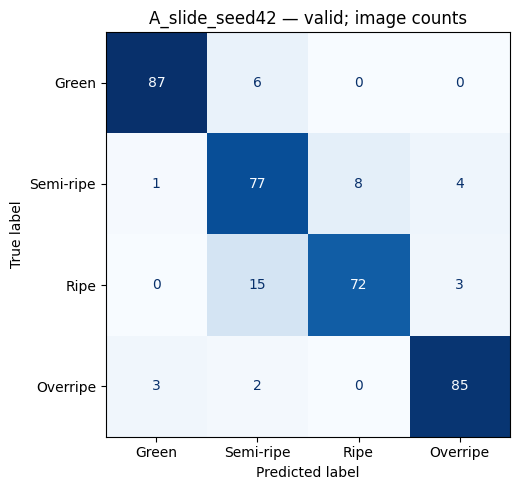

              precision    recall  f1-score   support

       Green     0.9560    0.9355    0.9457        93
   Semi-ripe     0.7700    0.8556    0.8105        90
        Ripe     0.9000    0.8000    0.8471        90
    Overripe     0.9239    0.9444    0.9341        90

    accuracy                         0.8843       363
   macro avg     0.8875    0.8839    0.8843       363
weighted avg     0.8881    0.8843    0.8848       363


Training B_features, seed=42
Epoch 1/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.2460 - loss: 1.3858 — val_macro_f1: 0.3427

Epoch 1: val_macro_f1 improved from None to 0.34272, saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/B_features_seed42/best_model.keras

Epoch 1: finished saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/B_features_seed42/best_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 147ms/step - accuracy: 0.2821 - loss: 1.3822 - val_accuracy: 0.4738 - val_loss: 1.3667 - val_macro_f1: 0.3427 - learning_rate: 

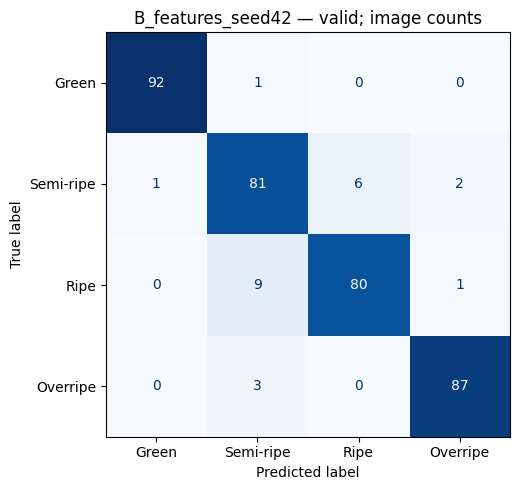

              precision    recall  f1-score   support

       Green     0.9892    0.9892    0.9892        93
   Semi-ripe     0.8617    0.9000    0.8804        90
        Ripe     0.9302    0.8889    0.9091        90
    Overripe     0.9667    0.9667    0.9667        90

    accuracy                         0.9366       363
   macro avg     0.9370    0.9362    0.9364       363
weighted avg     0.9374    0.9366    0.9368       363


Training C_bn_dropout, seed=42
Epoch 1/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.5204 - loss: 1.1716 — val_macro_f1: 0.7008

Epoch 1: val_macro_f1 improved from None to 0.70078, saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/C_bn_dropout_seed42/best_model.keras

Epoch 1: finished saving model to /kaggle/working/cnn_ABC_20261120_032542_537036/C_bn_dropout_seed42/best_model.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 168ms/step - accuracy: 0.6533 - loss: 0.9447 - val_accuracy: 0.7300 - val_loss: 0.8206 - val_macro_f1: 0.7008 - learning

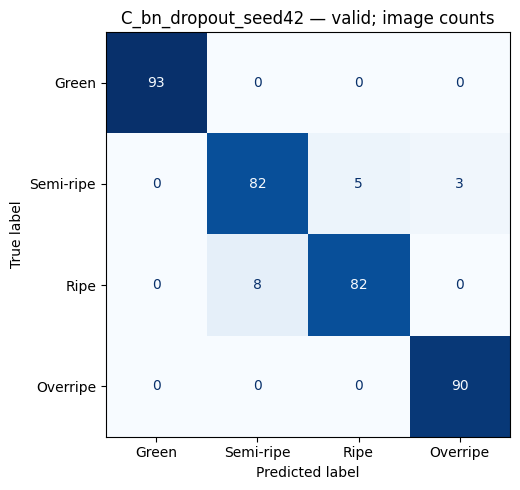

              precision    recall  f1-score   support

       Green     1.0000    1.0000    1.0000        93
   Semi-ripe     0.9111    0.9111    0.9111        90
        Ripe     0.9425    0.9111    0.9266        90
    Overripe     0.9677    1.0000    0.9836        90

    accuracy                         0.9559       363
   macro avg     0.9553    0.9556    0.9553       363
weighted avg     0.9557    0.9559    0.9557       363



In [7]:
class ValidationMacroF1(tf.keras.callbacks.Callback):
    def __init__(self, valid_dataset, y_true):
        super().__init__()
        self.valid_dataset = valid_dataset
        self.y_true = np.asarray(y_true)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        probabilities = self.model.predict(self.valid_dataset, verbose=0)
        y_pred = probabilities.argmax(axis=1)
        score = f1_score(self.y_true, y_pred, labels=range(len(CLASS_NAMES)), average="macro", zero_division=0)
        logs["val_macro_f1"] = float(score)
        print(f" — val_macro_f1: {score:.4f}")

results = []
for seed in TRAIN_SEEDS:
    for name in MODEL_NAMES:
        tf.keras.backend.clear_session(); gc.collect()
        tf.keras.utils.set_random_seed(seed)
        run_dir = OUTPUT / f"{name}_seed{seed}"
        run_dir.mkdir(exist_ok=False)
        model = build_model(name)
        model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        train_ds = make_dataset(train_df, training=True, seed=seed)
        valid_ds = make_dataset(valid_df)
        callbacks = [
            ValidationMacroF1(valid_ds, valid_df.label_id.to_numpy()),
            tf.keras.callbacks.ModelCheckpoint(str(run_dir / "best_model.keras"), monitor="val_macro_f1", mode="max", save_best_only=True, verbose=1),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_delta=0., min_lr=1e-6, verbose=1),
            tf.keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=PATIENCE, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.CSVLogger(str(run_dir / "training_log.csv")),
            tf.keras.callbacks.TerminateOnNaN()]
        print(f"\nTraining {name}, seed={seed}")
        start = time.perf_counter()
        history = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks)
        seconds = time.perf_counter() - start
        hist = pd.DataFrame(history.history)
        hist.index = np.arange(1, len(hist)+1); hist.index.name = "epoch"
        hist.to_csv(run_dir / "history.csv")
        assert np.isfinite(hist[["loss", "val_loss", "val_macro_f1"]].to_numpy()).all(), "Metric không hữu hạn; xem log"
        best_epoch = int(hist.val_macro_f1.idxmax())
        del model
        model = tf.keras.models.load_model(run_dir / "best_model.keras")
        row = dict(model=name, seed=seed, split_sha256=SPLIT_SHA, parameters=model.count_params(),
                   best_epoch=best_epoch, epochs_run=len(hist), fit_seconds=seconds,
                   best_val_loss=float(hist.loc[best_epoch, "val_loss"]), best_val_macro_f1=float(hist.val_macro_f1.max()), run_dir=str(run_dir))
        row.update(evaluate_model(model, valid_df, "valid", run_dir))
        (run_dir / "run_summary.json").write_text(json.dumps(row, indent=2), encoding="utf-8")
        results.append(row)
        pd.DataFrame(results).to_csv(OUTPUT / "validation_runs.csv", index=False)
        del model, train_ds, valid_ds
        gc.collect()


## So sánh kết quả
Độ lệch chuẩn mẫu tính trên các seed huấn luyện, không phải độ bất định do chia dữ liệu. Một seed không có SD (để NaN). Không chọn seed tốt nhất làm đại diện. Loss/accuracy lúc train của C chịu ảnh hưởng BN/Dropout, khác chế độ inference.


,model,seed,parameters,best_epoch,epochs_run,fit_seconds,best_val_loss,best_val_macro_f1,accuracy,macro_f1,images,split,recall_Green,recall_Semi-ripe,recall_Ripe,recall_Overripe
0,A_slide,42,1741496,24,36,331.176040,0.456922,0.884326,0.884298,0.884326,363,valid,0.935484,0.855556,0.800000,0.944444
1,B_features,42,110276,53,60,459.292266,0.157378,0.936360,0.936639,0.936360,363,valid,0.989247,0.900000,0.888889,0.966667
2,C_bn_dropout,42,110948,29,41,358.941173,0.123566,0.955318,0.955923,0.955318,363,valid,1.000000,0.911111,0.911111,1.000000


,runs,parameters,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,fit_seconds_mean
model,,,,,,,
A_slide,1,1741496,0.884298,NaN,0.884326,NaN,331.176040
B_features,1,110276,0.936639,NaN,0.936360,NaN,459.292266
C_bn_dropout,1,110948,0.955923,NaN,0.955318,NaN,358.941173


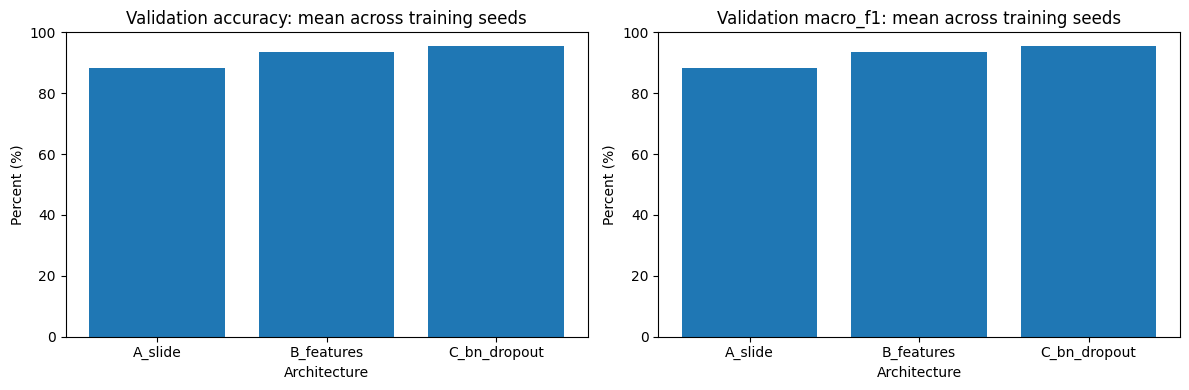

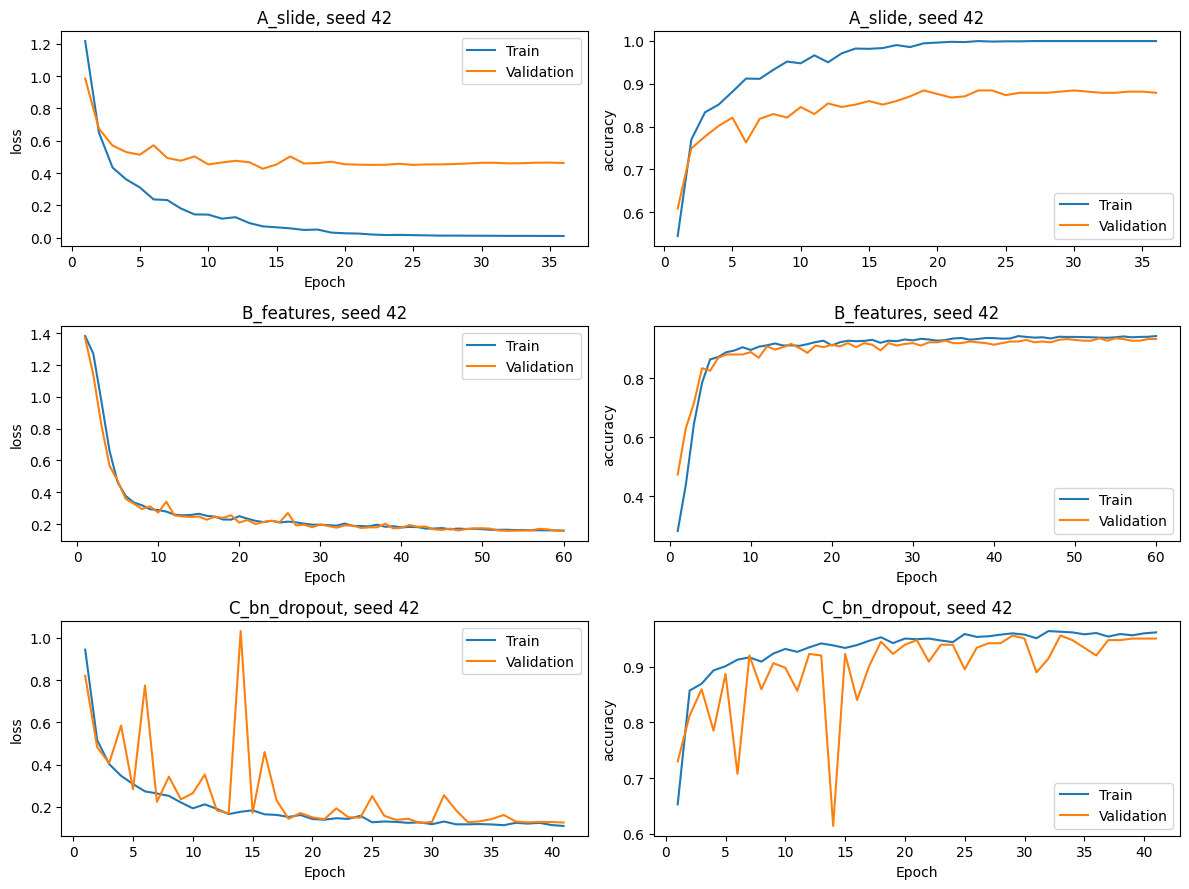

In [8]:
results_df = pd.DataFrame(results)
display(results_df.drop(columns=["run_dir", "split_sha256"]))
summary = results_df.groupby("model", sort=False).agg(
    runs=("seed", "count"), parameters=("parameters", "first"),
    accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    fit_seconds_mean=("fit_seconds", "mean"))
summary.to_csv(OUTPUT / "validation_summary.csv")
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
    ax.bar(summary.index, summary[metric+"_mean"]*100)
    if (summary.runs > 1).all():
        ax.errorbar(summary.index, summary[metric+"_mean"]*100,
                    yerr=summary[metric+"_std"]*100, fmt="none", color="black", capsize=4)
    ax.set(title=f"Validation {metric}: mean across training seeds", xlabel="Architecture", ylabel="Percent (%)", ylim=(0,100))
fig.tight_layout(); fig.savefig(OUTPUT / "validation_comparison.png", dpi=160)
plt.show(); plt.close(fig)
for seed in TRAIN_SEEDS:
    fig, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(12, 3*len(MODEL_NAMES)), squeeze=False)
    for row_axes, name in zip(axes, MODEL_NAMES):
        h = pd.read_csv(OUTPUT / f"{name}_seed{seed}" / "history.csv")
        for ax, metric in zip(row_axes, ["loss", "accuracy"]):
            ax.plot(h.epoch, h[metric], label="Train")
            ax.plot(h.epoch, h["val_"+metric], label="Validation")
            ax.set(title=f"{name}, seed {seed}", xlabel="Epoch", ylabel=metric)
            ax.legend()
    fig.tight_layout(); fig.savefig(OUTPUT / f"learning_curves_seed{seed}.png", dpi=150)
    plt.show(); plt.close(fig)


## Test cuối cùng — không huấn luyện lại
Sau khi chốt các cấu hình, đặt RUN_TEST=True ở cell cấu hình và chỉ chạy cell này. Đánh giá tất cả checkpoint đã chạy; không chọn model/seed theo test. Nếu phiên kernel đã mất, cần khôi phục OUTPUT, manifest và các hàm trước khi dùng; không Run All chỉ để xem test. SVM/MobileNet cần cùng danh sách ảnh test để so sánh.


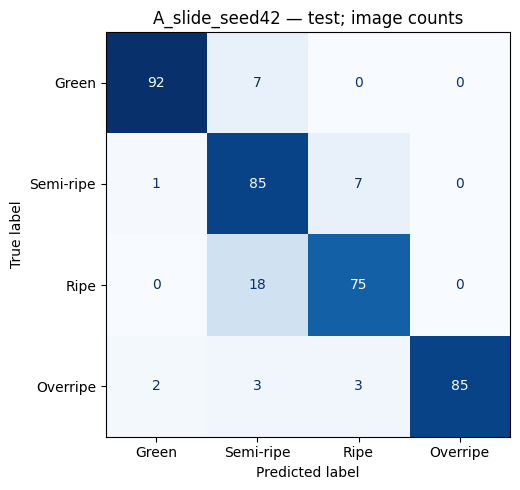

              precision    recall  f1-score   support

       Green     0.9684    0.9293    0.9485        99
   Semi-ripe     0.7522    0.9140    0.8252        93
        Ripe     0.8824    0.8065    0.8427        93
    Overripe     1.0000    0.9140    0.9551        93

    accuracy                         0.8915       378
   macro avg     0.9007    0.8909    0.8929       378
weighted avg     0.9018    0.8915    0.8937       378



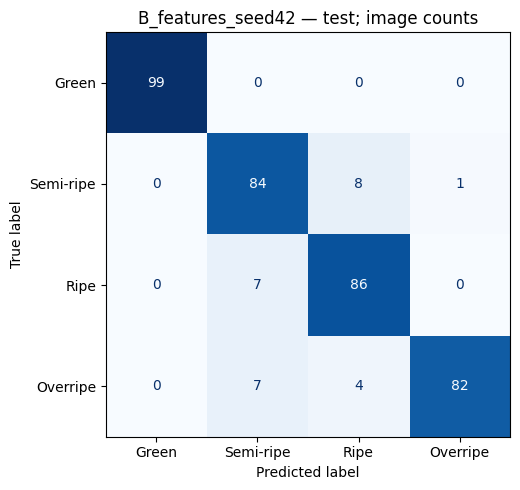

              precision    recall  f1-score   support

       Green     1.0000    1.0000    1.0000        99
   Semi-ripe     0.8571    0.9032    0.8796        93
        Ripe     0.8776    0.9247    0.9005        93
    Overripe     0.9880    0.8817    0.9318        93

    accuracy                         0.9286       378
   macro avg     0.9307    0.9274    0.9280       378
weighted avg     0.9318    0.9286    0.9291       378



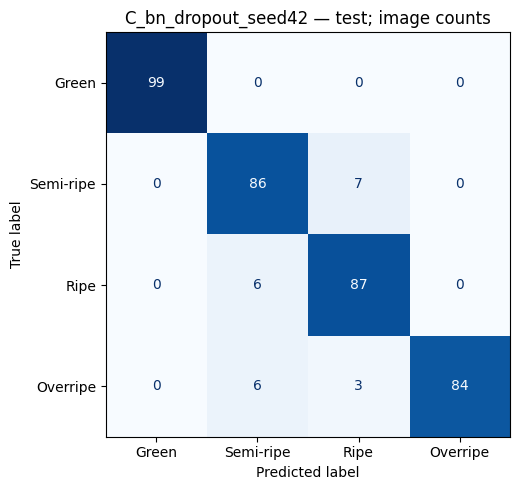

              precision    recall  f1-score   support

       Green     1.0000    1.0000    1.0000        99
   Semi-ripe     0.8776    0.9247    0.9005        93
        Ripe     0.8969    0.9355    0.9158        93
    Overripe     1.0000    0.9032    0.9492        93

    accuracy                         0.9418       378
   macro avg     0.9436    0.9409    0.9414       378
weighted avg     0.9445    0.9418    0.9423       378



,model,seed,split_sha256,accuracy,macro_f1,images,split,recall_Green,recall_Semi-ripe,recall_Ripe,recall_Overripe
0,A_slide,42,fd00e11b0028b8dd68fa9d3441d4e5f14f2cfe62cb853d...,0.891534,0.892862,378,test,0.929293,0.913978,0.806452,0.913978
1,B_features,42,fd00e11b0028b8dd68fa9d3441d4e5f14f2cfe62cb853d...,0.928571,0.927981,378,test,1.000000,0.903226,0.924731,0.881720
2,C_bn_dropout,42,fd00e11b0028b8dd68fa9d3441d4e5f14f2cfe62cb853d...,0.941799,0.941366,378,test,1.000000,0.924731,0.935484,0.903226


,runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
model,,,,,
A_slide,1,0.891534,NaN,0.892862,NaN
B_features,1,0.928571,NaN,0.927981,NaN
C_bn_dropout,1,0.941799,NaN,0.941366,NaN


In [11]:
RUN_TEST = True  # Bỏ dấu # khi đã sẵn sàng đánh giá cuối
if RUN_TEST:
    test_frame = df[df.split.eq("test")].reset_index(drop=True)
    saved_runs = pd.read_csv(OUTPUT / "validation_runs.csv")
    test_rows = []
    for item in saved_runs.itertuples():
        tf.keras.backend.clear_session()
        run_dir = OUTPUT / f"{item.model}_seed{item.seed}"
        model = tf.keras.models.load_model(run_dir / "best_model.keras")
        metrics = evaluate_model(model, test_frame, "test", run_dir)
        test_rows.append(dict(model=item.model, seed=item.seed, split_sha256=SPLIT_SHA, **metrics))
        del model; gc.collect()
    test_results = pd.DataFrame(test_rows)
    test_results.to_csv(OUTPUT / "test_runs.csv", index=False)
    test_summary = test_results.groupby("model").agg(
        runs=("seed","count"), accuracy_mean=("accuracy","mean"), accuracy_std=("accuracy","std"),
        macro_f1_mean=("macro_f1","mean"), macro_f1_std=("macro_f1","std"))
    test_summary.to_csv(OUTPUT / "test_summary.csv")
    display(test_results); display(test_summary)
else:
    print("Chưa đánh giá test.")


In [12]:
archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT)
print("Kết quả:", OUTPUT)
print("ZIP:", archive)
# Nếu vừa chạy test sau đó, chạy lại cell này để ZIP có kết quả test.


Kết quả: /kaggle/working/cnn_ABC_20261120_032542_537036
ZIP: /kaggle/working/cnn_ABC_20261120_032542_537036.zip
